# Phase 3: Exploratory Data Analysis (EDA)
Predictive Maintenance of Industrial Equipment using IoT Sensor Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
df = pd.read_csv('../data/cleaned_sensor_data.csv', parse_dates=['Timestamp'])
df.shape

(86400, 12)

## 3.1 Failure rate by machine

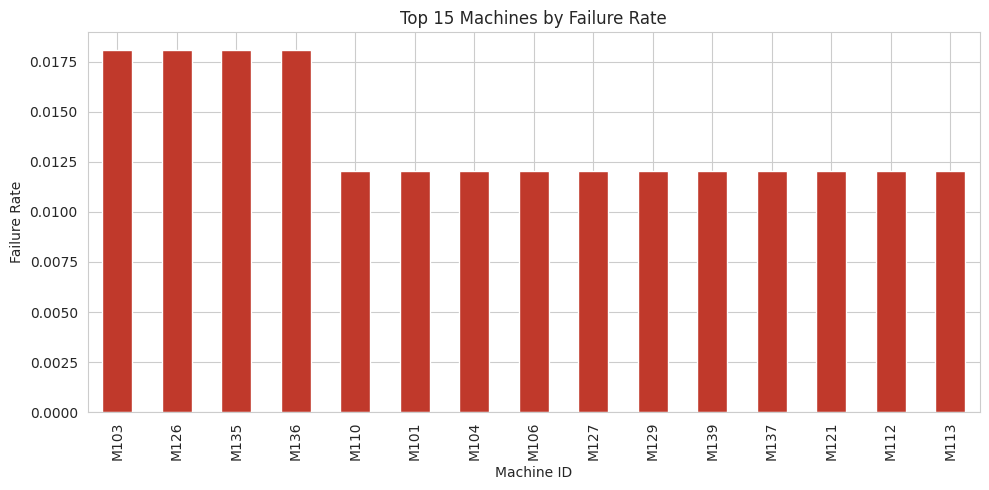

In [2]:
failure_by_machine = df.groupby('Machine_ID')['Failure'].mean().sort_values(ascending=False)
plt.figure(figsize=(10,5))
failure_by_machine.head(15).plot(kind='bar', color='#c0392b')
plt.title('Top 15 Machines by Failure Rate')
plt.ylabel('Failure Rate'); plt.xlabel('Machine ID')
plt.tight_layout(); plt.savefig('../outputs/failure_by_machine.png', dpi=110); plt.show()

**Observation:** Failure risk is not evenly spread across the fleet — a handful of machines account for a disproportionate share of failure events, which is exactly the kind of insight a maintenance manager needs to prioritize inspections.

## 3.2 Temperature distribution and its relationship with failure

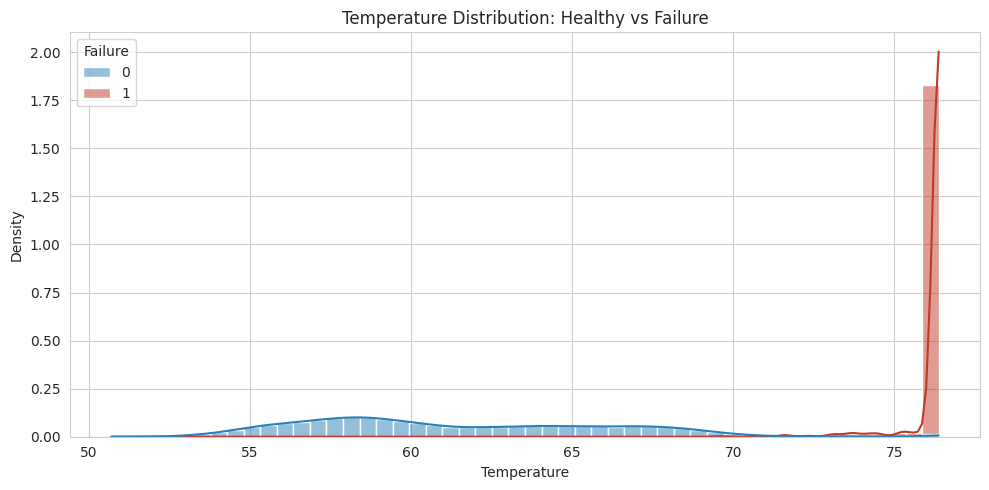

In [3]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Temperature', hue='Failure', bins=50, kde=True, palette=['#2980b9','#c0392b'], stat='density', common_norm=False)
plt.title('Temperature Distribution: Healthy vs Failure')
plt.tight_layout(); plt.savefig('../outputs/temp_distribution.png', dpi=110); plt.show()

## 3.3 Vibration distribution and its relationship with failure

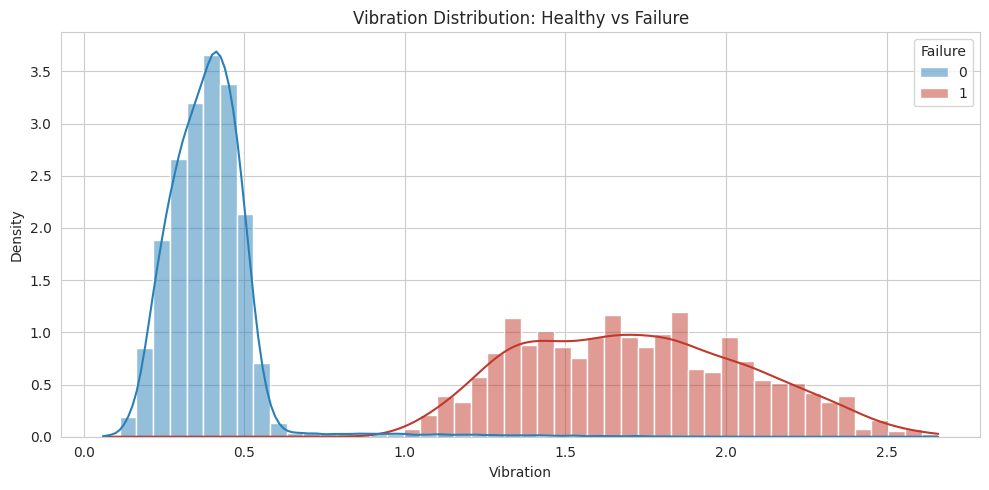

In [4]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Vibration', hue='Failure', bins=50, kde=True, palette=['#2980b9','#c0392b'], stat='density', common_norm=False)
plt.title('Vibration Distribution: Healthy vs Failure')
plt.tight_layout(); plt.savefig('../outputs/vibration_distribution.png', dpi=110); plt.show()

**Observation:** Failure readings are clearly shifted toward higher temperature and higher vibration compared to healthy readings — confirming these two sensors as strong candidate predictors.

## 3.4 Pressure and RPM patterns (box plots)

/tmp/ipykernel_163/666065952.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Failure', y='Pressure', ax=axes[0], palette=['#2980b9','#c0392b'])
/tmp/ipykernel_163/666065952.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Failure', y='RPM', ax=axes[1], palette=['#2980b9','#c0392b'])


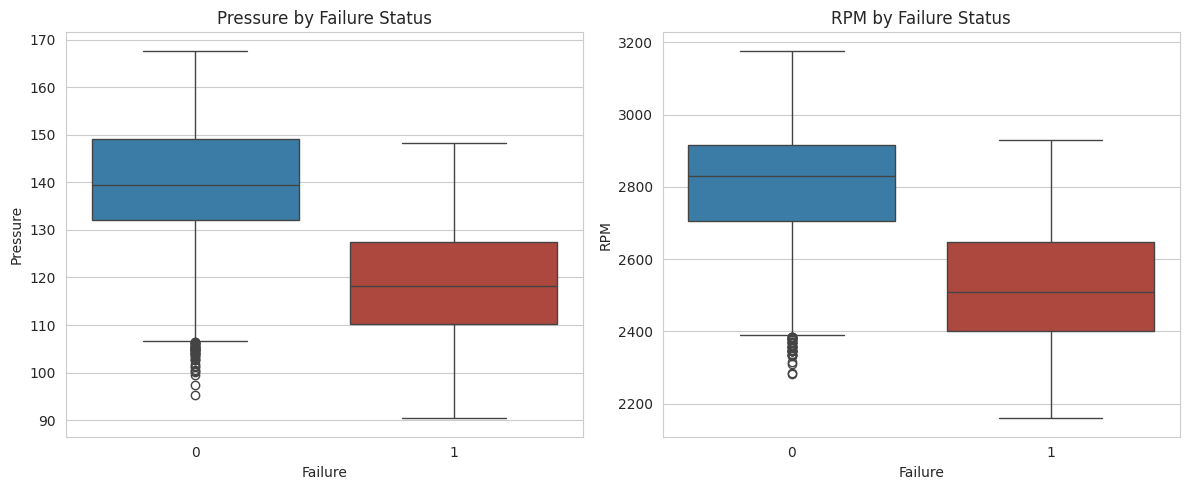

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(data=df, x='Failure', y='Pressure', ax=axes[0], palette=['#2980b9','#c0392b'])
axes[0].set_title('Pressure by Failure Status')
sns.boxplot(data=df, x='Failure', y='RPM', ax=axes[1], palette=['#2980b9','#c0392b'])
axes[1].set_title('RPM by Failure Status')
plt.tight_layout(); plt.savefig('../outputs/pressure_rpm_boxplots.png', dpi=110); plt.show()

**Observation:** Failing machines show noticeably lower Pressure and lower RPM — consistent with mechanical strain/underperformance before breakdown.

## 3.5 Machine failure over time (time-series trend)

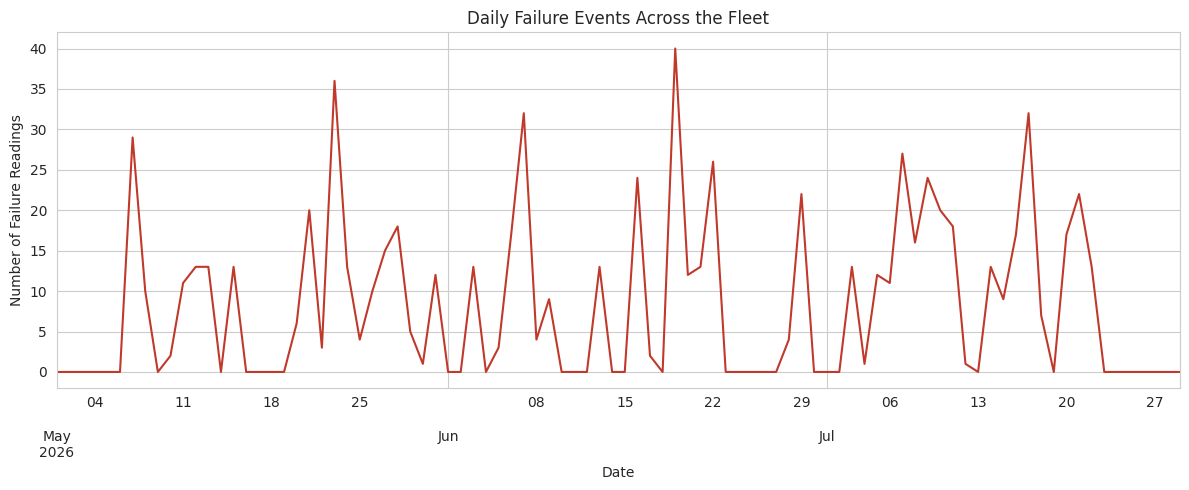

In [6]:
daily = df.set_index('Timestamp').resample('D')['Failure'].sum()
plt.figure(figsize=(12,5))
daily.plot(color='#c0392b')
plt.title('Daily Failure Events Across the Fleet')
plt.ylabel('Number of Failure Readings'); plt.xlabel('Date')
plt.tight_layout(); plt.savefig('../outputs/failure_trend_time.png', dpi=110); plt.show()

## 3.6 Correlation between sensor variables (heatmap)

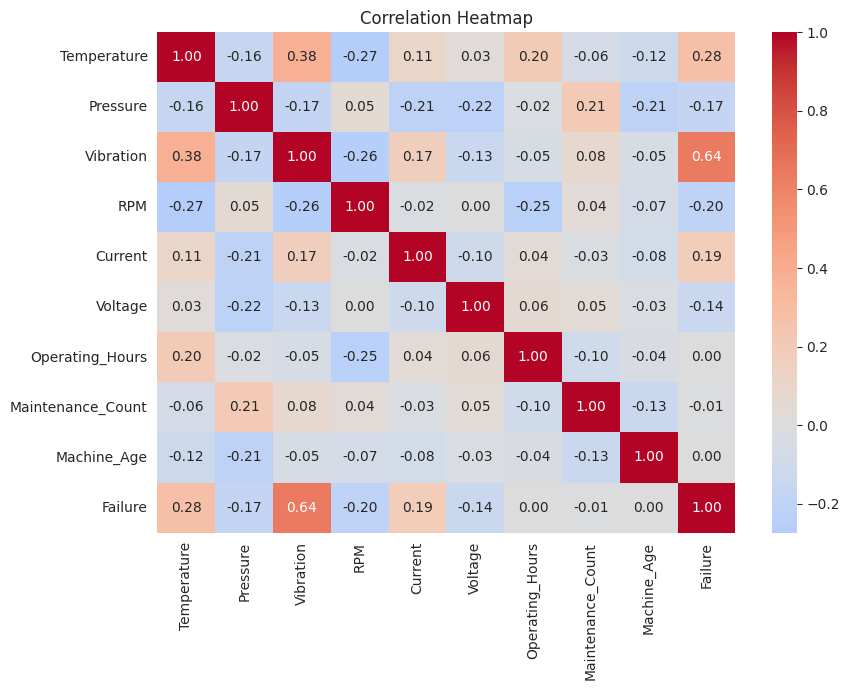

In [7]:
num_cols = ['Temperature','Pressure','Vibration','RPM','Current','Voltage',
            'Operating_Hours','Maintenance_Count','Machine_Age','Failure']
plt.figure(figsize=(9,7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout(); plt.savefig('../outputs/correlation_heatmap.png', dpi=110); plt.show()

**Observation:** Temperature and Vibration show the strongest positive correlation with Failure; Pressure and RPM show negative correlation — consistent with the distribution/box plots above.

## 3.7 Machines with unusual/abnormal sensor behavior (anomaly scan)

In [8]:
machine_stats = df.groupby('Machine_ID')[['Temperature','Vibration']].mean().round(2)
machine_stats['Temp_Zscore'] = (machine_stats['Temperature'] - machine_stats['Temperature'].mean()) / machine_stats['Temperature'].std()
abnormal_machines = machine_stats[abs(machine_stats['Temp_Zscore']) > 1.5].sort_values('Temp_Zscore', ascending=False)
abnormal_machines

,Temperature,Vibration,Temp_Zscore
Machine_ID,,,
M135,69.50,0.29,1.893085
M127,68.72,0.43,1.708895
M116,68.18,0.36,1.581378
M119,55.02,0.34,-1.526239


**Observation:** These machines run at average temperatures noticeably outside the fleet norm and warrant closer inspection regardless of their failure label.

## 3.8 Operating hours vs failure occurrence

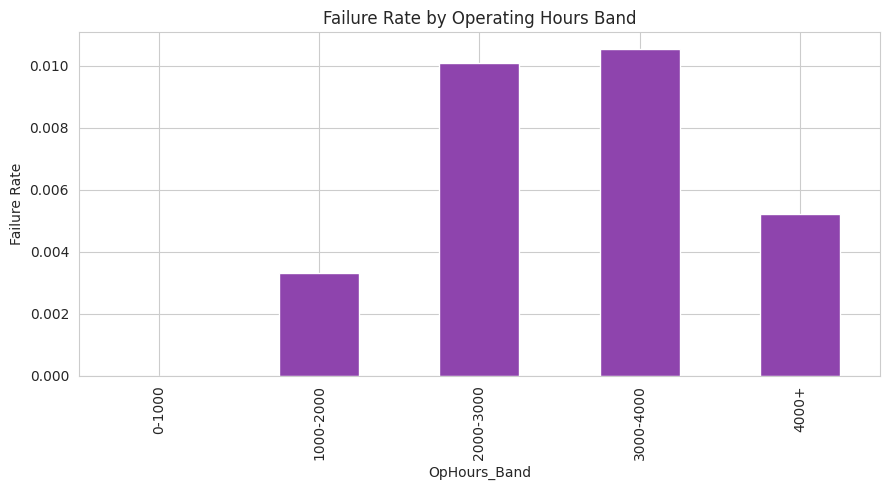

In [9]:
df['OpHours_Band'] = pd.cut(df['Operating_Hours'], bins=[0,1000,2000,3000,4000,6000],
                            labels=['0-1000','1000-2000','2000-3000','3000-4000','4000+'])
failure_by_hours = df.groupby('OpHours_Band')['Failure'].mean()
plt.figure(figsize=(9,5))
failure_by_hours.plot(kind='bar', color='#8e44ad')
plt.title('Failure Rate by Operating Hours Band')
plt.ylabel('Failure Rate')
plt.tight_layout(); plt.savefig('../outputs/failure_by_ophours.png', dpi=110); plt.show()

**Observation:** Failure rate increases with cumulative operating hours, supporting the intuition that machine wear accumulates with usage — Operating_Hours is a meaningful feature for modeling.

## Summary of EDA Findings
- Failure risk is concentrated in a subset of machines, not evenly distributed.
- Temperature and Vibration rise sharply before failure; Pressure and RPM drop.
- Failure rate increases with Operating_Hours, confirming a wear-and-tear relationship.
- A handful of machines run at abnormal average temperatures and should be flagged for inspection independent of the model's prediction.
- Dataset is highly imbalanced (~0.9% failure rate) — this must be handled explicitly during modeling (class weighting / evaluation focused on recall & F1, not just accuracy).